<a href="https://colab.research.google.com/github/ChanikyaMysur/MLA0403_DeepLearning/blob/main/CO1_Experiments_(1-6).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Vector u: [3. 2.]
Vector v: [1. 4.]
Dot Product (u . v): 11.0
L1 Norm of u: 5.0
L2 Norm of u: 3.6056

Matrix A:
 [[2 1]
 [1 3]]
Matrix B:
 [[1 0]
 [2 1]]
Matrix Product (A @ B):
 [[4 1]
 [7 3]]
Transpose of A:
 [[2 1]
 [1 3]]


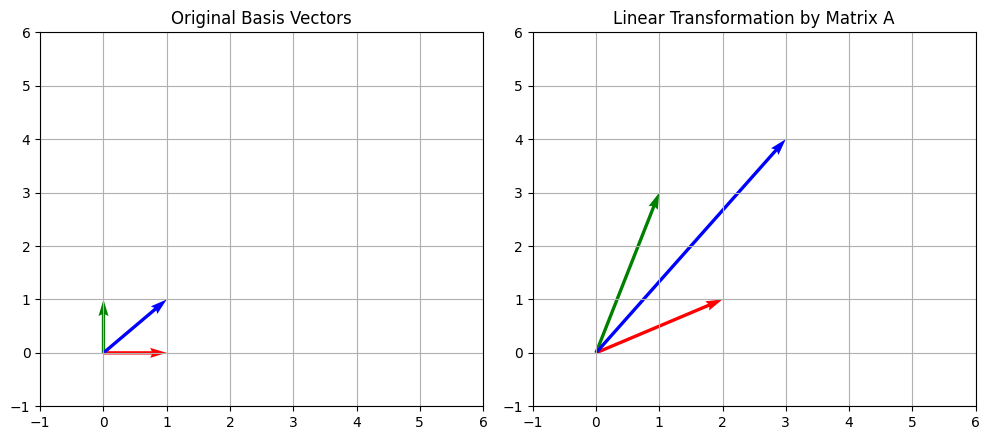

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Vector Setup & Operations
u = np.array([3.0, 2.0])
v = np.array([1.0, 4.0])

dot_product = np.dot(u, v)
l1_norm = np.linalg.norm(u, ord=1)
l2_norm = np.linalg.norm(u, ord=2)

print(f"Vector u: {u}")
print(f"Vector v: {v}")
print(f"Dot Product (u . v): {dot_product}")
print(f"L1 Norm of u: {l1_norm}")
print(f"L2 Norm of u: {l2_norm:.4f}\n")

# 2. Matrix Multiplication & Transpose
A = np.array([[2, 1],
              [1, 3]])
B = np.array([[1, 0],
              [2, 1]])

matrix_mult = A @ B  # Equivalent to np.dot(A, B)
transpose_A = A.T

print("Matrix A:\n", A)
print("Matrix B:\n", B)
print("Matrix Product (A @ B):\n", matrix_mult)
print("Transpose of A:\n", transpose_A)

# 3. Visualizing Vector Linear Transformations
vectors = np.array([[1, 0], [0, 1], [1, 1]]).T  # Basis vectors & diagonal
transformed = A @ vectors

plt.figure(figsize=(10, 4.5))

plt.subplot(1, 2, 1)
plt.quiver([0, 0, 0], [0, 0, 0], vectors[0, :], vectors[1, :],
           angles='xy', scale_units='xy', scale=1, color=['r', 'g', 'b'])
plt.xlim(-1, 6)
plt.ylim(-1, 6)
plt.title("Original Basis Vectors")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.quiver([0, 0, 0], [0, 0, 0], transformed[0, :], transformed[1, :],
           angles='xy', scale_units='xy', scale=1, color=['r', 'g', 'b'])
plt.xlim(-1, 6)
plt.ylim(-1, 6)
plt.title("Linear Transformation by Matrix A")
plt.grid(True)

plt.tight_layout()
plt.show()

Pandas Sample Covariance Matrix:
           Feature_1  Feature_2
Feature_1   2.099834   3.759817
Feature_2   3.759817   7.369413

NumPy Covariance Matrix:
[[2.09983442 3.75981673]
 [3.75981673 7.36941321]]

Eigenvalues: [9.32573882 0.14350881]
Eigenvectors (Columns):
 [[-0.46157947 -0.88709886]
 [-0.88709886  0.46157947]]


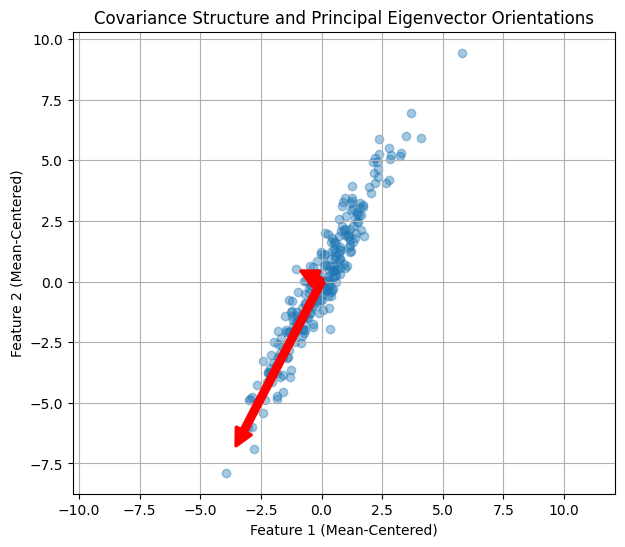

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Synthetic Correlated Dataset Generation
np.random.seed(42)
x = np.random.normal(loc=0, scale=1.5, size=250)
y = 1.8 * x + np.random.normal(loc=0, scale=0.8, size=250)

df = pd.DataFrame({'Feature_1': x, 'Feature_2': y})

# 2. Mean Centering & Covariance Analysis
df_centered = df - df.mean()
cov_matrix = np.cov(df_centered.T)

print("Pandas Sample Covariance Matrix:")
print(df.cov())
print("\nNumPy Covariance Matrix:")
print(cov_matrix)

# 3. Eigen-Decomposition
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)

# Sort Eigenvalues/Eigenvectors descending
sort_indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sort_indices]
eigenvectors = eigenvectors[:, sort_indices]

print("\nEigenvalues:", eigenvalues)
print("Eigenvectors (Columns):\n", eigenvectors)

# 4. Plotting Data and Principal Axes (Eigenvectors)
plt.figure(figsize=(7, 6))
plt.scatter(df_centered['Feature_1'], df_centered['Feature_2'], alpha=0.4, label='Data Points')

# Draw Eigenvectors scaled by standard deviations (sqrt of Eigenvalues)
for eval_val, evec in zip(eigenvalues, eigenvectors.T):
    endpoint = evec * np.sqrt(eval_val) * 2.5
    plt.annotate('', xy=endpoint, xytext=(0, 0),
                 arrowprops=dict(facecolor='red', edgecolor='red', lw=2.5))

plt.xlabel('Feature 1 (Mean-Centered)')
plt.ylabel('Feature 2 (Mean-Centered)')
plt.title('Covariance Structure and Principal Eigenvector Orientations')
plt.grid(True)
plt.axis('equal')
plt.show()

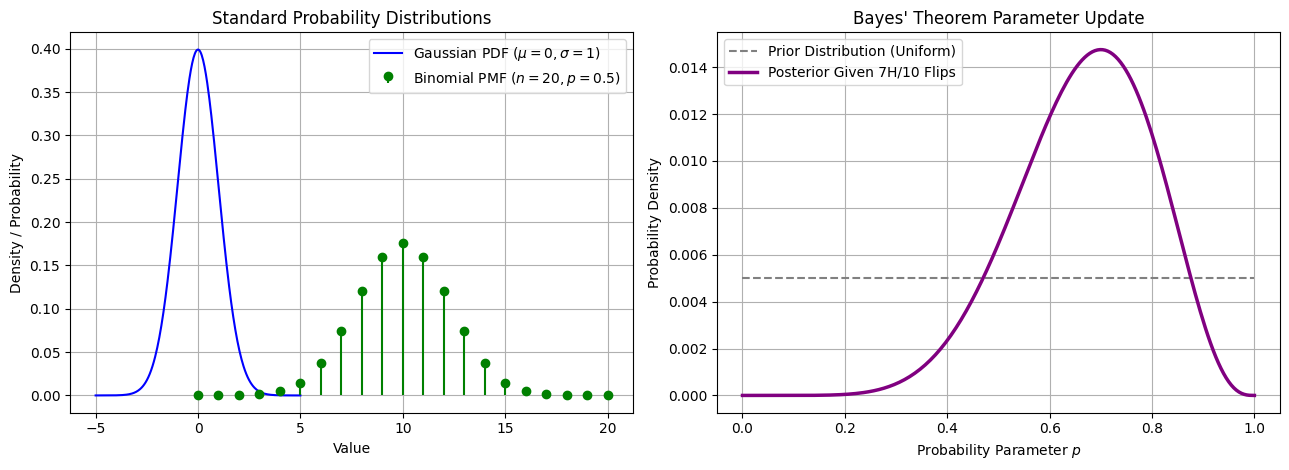

In [8]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# 1. Probability Distributions Setup
x_continuous = np.linspace(-5, 5, 300)
gaussian_pdf = stats.norm.pdf(x_continuous, loc=0, scale=1)

k_discrete = np.arange(0, 21)
binomial_pmf = stats.binom.pmf(k_discrete, n=20, p=0.5)

# 2. Sequential Bayes' Theorem Simulation (Coin Bias Estimation)
p_grid = np.linspace(0, 1, 200)
prior = np.ones_like(p_grid) / len(p_grid)  # Uniform Flat Prior

# Observed Data: 7 Heads in 10 Flips
k_heads, n_trials = 7, 10
likelihood = stats.binom.pmf(k_heads, n=n_trials, p=p_grid)

unnormalized_posterior = likelihood * prior
posterior = unnormalized_posterior / np.sum(unnormalized_posterior)

# 3. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Subplot 1: Standard Distributions (Fixed raw strings r'...')
axes[0].plot(x_continuous, gaussian_pdf, label=r'Gaussian PDF ($\mu=0, \sigma=1$)', color='blue')
axes[0].stem(k_discrete, binomial_pmf, linefmt='green', markerfmt='go', basefmt=" ", label=r'Binomial PMF ($n=20, p=0.5$)')
axes[0].set_title('Standard Probability Distributions')
axes[0].set_xlabel('Value')
axes[0].set_ylabel('Density / Probability')
axes[0].legend()
axes[0].grid(True)

# Subplot 2: Bayesian Parameter Updating
axes[1].plot(p_grid, prior, label='Prior Distribution (Uniform)', linestyle='--', color='gray')
axes[1].plot(p_grid, posterior, label=f'Posterior Given {k_heads}H/{n_trials} Flips', color='purple', lw=2.5)
axes[1].set_title("Bayes' Theorem Parameter Update")
axes[1].set_xlabel(r'Probability Parameter $p$')
axes[1].set_ylabel('Probability Density')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Shannon Entropy H(P):               1.5589 bits
Cross-Entropy H(P, Q):              1.6500 bits
KL Divergence D_KL(P || Q) [Manual]: 0.0911 bits
KL Divergence D_KL(P || Q) [SciPy]:  0.0911 bits


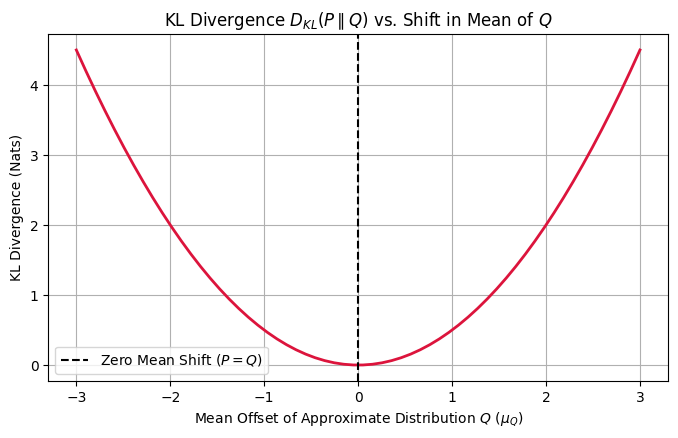

In [9]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# 1. Discrete Distributions Setup
P = np.array([0.40, 0.35, 0.25])  # True distribution
Q = np.array([0.25, 0.50, 0.25])  # Approximate distribution

eps = 1e-12
P_safe = np.clip(P, eps, 1.0)
Q_safe = np.clip(Q, eps, 1.0)

# Information Metrics Computations (in bits using base 2)
shannon_entropy = -np.sum(P_safe * np.log2(P_safe))
cross_entropy = -np.sum(P_safe * np.log2(Q_safe))
kl_div_manual = np.sum(P_safe * np.log2(P_safe / Q_safe))
kl_div_scipy = stats.entropy(P, Q, base=2)

print(f"Shannon Entropy H(P):               {shannon_entropy:.4f} bits")
print(f"Cross-Entropy H(P, Q):              {cross_entropy:.4f} bits")
print(f"KL Divergence D_KL(P || Q) [Manual]: {kl_div_manual:.4f} bits")
print(f"KL Divergence D_KL(P || Q) [SciPy]:  {kl_div_scipy:.4f} bits")

# 2. Continuous KL Divergence Analysis (Distribution Shift)
x = np.linspace(-6, 6, 500)
p_pdf = stats.norm.pdf(x, loc=0, scale=1.0)

shift_means = np.linspace(-3, 3, 60)
kl_divergences = []

for mean in shift_means:
    q_pdf = stats.norm.pdf(x, loc=mean, scale=1.0)
    # Numerical integration of KL divergence
    kl_val = stats.entropy(p_pdf, q_pdf)
    kl_divergences.append(kl_val)

plt.figure(figsize=(8, 4.5))
plt.plot(shift_means, kl_divergences, color='crimson', lw=2)
plt.axvline(0, color='black', linestyle='--', label='Zero Mean Shift ($P=Q$)')

# Fixed raw strings applied below:
plt.title(r'KL Divergence $D_{KL}(P \parallel Q)$ vs. Shift in Mean of $Q$')
plt.xlabel(r'Mean Offset of Approximate Distribution $Q$ ($\mu_Q$)')
plt.ylabel('KL Divergence (Nats)')
plt.grid(True)
plt.legend()
plt.show()

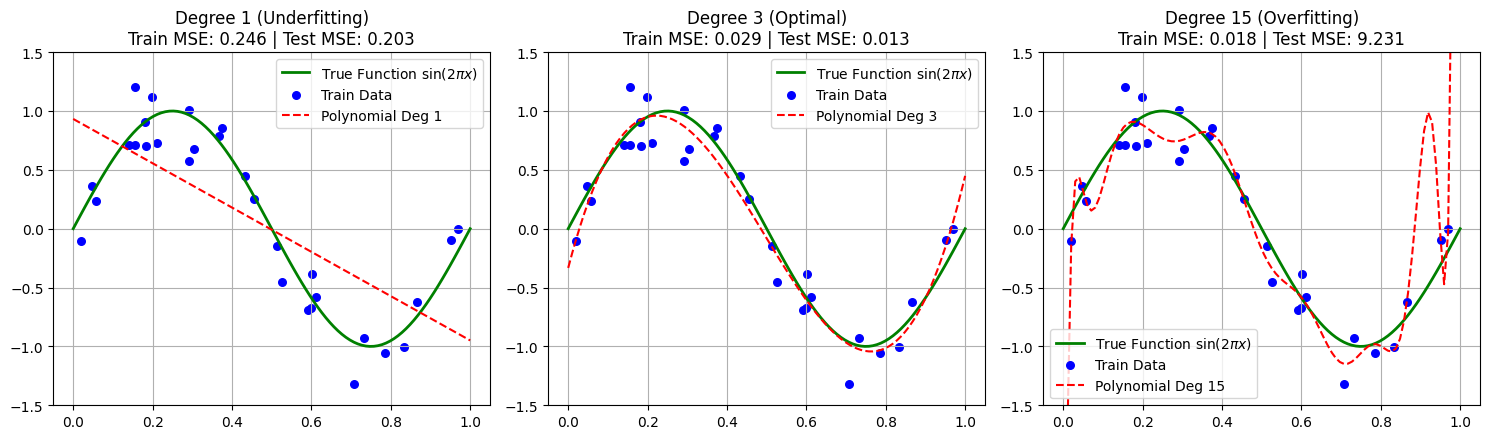

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# 1. Synthetic Non-Linear Dataset Generation
np.random.seed(42)
n_samples = 30
x_train = np.sort(np.random.rand(n_samples))
y_train = np.sin(2 * np.pi * x_train) + np.random.normal(0, 0.2, n_samples)

x_test = np.linspace(0, 1, 100)
y_test = np.sin(2 * np.pi * x_test)  # True underlying function

degrees = [1, 3, 15]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for i, deg in enumerate(degrees):
    # Pipeline: Polynomial feature transformation + Linear Regression
    model = make_pipeline(PolynomialFeatures(deg), LinearRegression())
    model.fit(x_train[:, np.newaxis], y_train)

    y_train_pred = model.predict(x_train[:, np.newaxis])
    y_test_pred = model.predict(x_test[:, np.newaxis])

    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)

    ax = axes[i]
    # Fixed raw string applied below:
    ax.plot(x_test, y_test, label=r'True Function $\sin(2\pi x)$', color='green', lw=2)
    ax.scatter(x_train, y_train, color='blue', s=30, label='Train Data')
    ax.plot(x_test, y_test_pred, label=f'Polynomial Deg {deg}', color='red', linestyle='--')
    ax.set_ylim(-1.5, 1.5)

    status = "Underfitting" if deg == 1 else ("Optimal" if deg == 3 else "Overfitting")
    ax.set_title(f"Degree {deg} ({status})\nTrain MSE: {train_mse:.3f} | Test MSE: {test_mse:.3f}")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

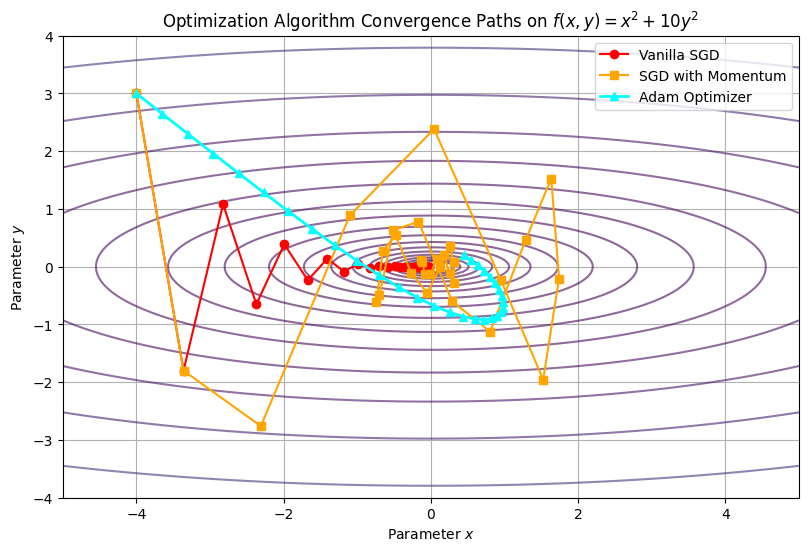

In [11]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Non-Convex Anisotropic Loss Function: f(x, y) = x^2 + 10*y^2
def loss_func(x, y):
    return x**2 + 10.0 * y**2

# 2. Optimization Routine using TensorFlow / Keras Optimizers
def run_tf_optimizer(optimizer, steps=30, start=(-4.0, 3.0)):
    x = tf.Variable(start[0], dtype=tf.float32)
    y = tf.Variable(start[1], dtype=tf.float32)
    trajectory = [[x.numpy(), y.numpy()]]

    for _ in range(steps):
        with tf.GradientTape() as tape:
            loss = loss_func(x, y)
        grads = tape.gradient(loss, [x, y])
        optimizer.apply_gradients(zip(grads, [x, y]))
        trajectory.append([x.numpy(), y.numpy()])

    return np.array(trajectory)

# 3. Compute Convergence Paths via Keras Optimizers
path_sgd = run_tf_optimizer(tf.keras.optimizers.SGD(learning_rate=0.08))
path_momentum = run_tf_optimizer(tf.keras.optimizers.SGD(learning_rate=0.08, momentum=0.8))
path_adam = run_tf_optimizer(tf.keras.optimizers.Adam(learning_rate=0.35))

# 4. Contour Visualization over Loss Surface
X, Y = np.meshgrid(np.linspace(-5, 5, 250), np.linspace(-4, 4, 250))
Z = loss_func(X, Y)

plt.figure(figsize=(9.5, 6))
plt.contour(X, Y, Z, levels=np.logspace(-1, 3, 20), cmap='viridis', alpha=0.6)

plt.plot(path_sgd[:, 0], path_sgd[:, 1], 'o-', label='Vanilla SGD', color='red', lw=1.5)
plt.plot(path_momentum[:, 0], path_momentum[:, 1], 's-', label='SGD with Momentum', color='orange', lw=1.5)
plt.plot(path_adam[:, 0], path_adam[:, 1], '^-', label='Adam Optimizer', color='cyan', lw=2)

# Raw strings applied defensively:
plt.title(r'Optimization Algorithm Convergence Paths on $f(x, y) = x^2 + 10y^2$')
plt.xlabel(r'Parameter $x$')
plt.ylabel(r'Parameter $y$')
plt.legend()
plt.grid(True)
plt.show()